# Estudo experimental — preparação dos perfis de consumo
Notebook reorganizado para evitar diagnósticos e gráficos repetidos. A análise mantém 24 médias horárias por dia e não realiza tratamento de outliers.

## 1. Carregamento e inspeção inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
print("Dimensões da base:", df.shape)
display(df.head())
display(df.tail())
df.info()

Dimensões da base: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2075258,26/11/2010,21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [2]:
print("Tipos das colunas:")
print(df.dtypes)
print("\nValores ausentes por coluna:")
print(df.isna().sum())
print("Linhas com pelo menos um valor ausente:", df.isna().any(axis=1).sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores distintos por coluna:")
print(df.nunique())
display(df.describe())

Tipos das colunas:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Valores ausentes por coluna:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64
Linhas com pelo menos um valor ausente: 25979
Linhas duplicadas: 0
Valores distintos por coluna:
Date                     1442
Time                     1440
Global_active_power      4186
Global_reactive_power     532
Voltage                  2837
Global_intensity          221
Sub_metering_1             88
Sub_metering_2             81
Sub_meterin

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


## 2. Diagnóstico temporal e de valores ausentes

In [3]:
df_diagnostico = df[["Date", "Time", "Global_active_power"]].copy()
df_diagnostico["DataHora"] = pd.to_datetime(
    df_diagnostico["Date"] + " " + df_diagnostico["Time"],
    format="%d/%m/%Y %H:%M:%S", errors="coerce"
)
if df_diagnostico["DataHora"].isna().any():
    raise ValueError("Existem datas ou horários inválidos.")
df_diagnostico["Dia"] = df_diagnostico["DataHora"].dt.date
df_diagnostico["Hora"] = df_diagnostico["DataHora"].dt.hour
print("Dias distintos:", df_diagnostico["Dia"].nunique())
print("Horários distintos:", df["Time"].nunique())
print("Intervalos entre medições:")
print(df_diagnostico["DataHora"].diff().value_counts().head(10))

Dias distintos: 1442
Horários distintos: 1440
Intervalos entre medições:
DataHora
0 days 00:01:00    2075258
Name: count, dtype: int64


In [4]:
diagnostico_dias = df_diagnostico.groupby("Dia")["Global_active_power"].agg(
    total_registros="size", valores_validos="count"
)
diagnostico_dias["valores_ausentes"] = (
    diagnostico_dias["total_registros"] - diagnostico_dias["valores_validos"]
)
diagnostico_dias["percentual_ausentes"] = (
    100 * diagnostico_dias["valores_ausentes"] / diagnostico_dias["total_registros"]
)
print("Dias com valores ausentes:", (diagnostico_dias["valores_ausentes"] > 0).sum())
print("Dias sem valores ausentes:", (diagnostico_dias["valores_ausentes"] == 0).sum())
display(diagnostico_dias["valores_ausentes"].describe())
display(diagnostico_dias.nlargest(10, "percentual_ausentes"))

Dias com valores ausentes: 82
Dias sem valores ausentes: 1360


count    1442.000000
mean       18.015950
std       149.424491
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1440.000000
Name: valores_ausentes, dtype: float64

,total_registros,valores_validos,valores_ausentes,percentual_ausentes
Dia,,,,
2007-04-29,1440,0,1440,100.000000
2009-06-14,1440,0,1440,100.000000
2010-01-13,1440,0,1440,100.000000
2010-08-18,1440,0,1440,100.000000
2010-08-19,1440,0,1440,100.000000
2010-08-20,1440,0,1440,100.000000
2010-08-21,1440,0,1440,100.000000
2010-09-26,1440,0,1440,100.000000
2010-09-27,1440,0,1440,100.000000


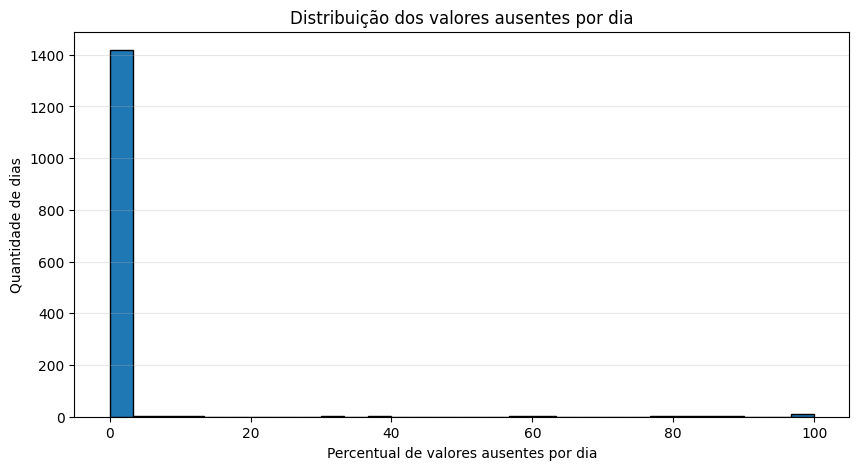

In [5]:
plt.figure(figsize=(10, 5))
plt.hist(diagnostico_dias["percentual_ausentes"], bins=30, edgecolor="black")
plt.xlabel("Percentual de valores ausentes por dia")
plt.ylabel("Quantidade de dias")
plt.title("Distribuição dos valores ausentes por dia")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 3. Completude horária
Uma hora é considerada adequada com pelo menos 48 das 60 medições esperadas (80%). Horas sem registros são preenchidas com zero na contagem.

In [6]:
agrupamento_horario = df_diagnostico.groupby(["Dia", "Hora"])["Global_active_power"]
validos_por_hora = agrupamento_horario.count().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
ausentes_por_hora = agrupamento_horario.apply(lambda x: x.isna().sum()).unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
print("Ausências por dia e hora:")
display(ausentes_por_hora.head())
print("Dias com pelo menos uma hora incompleta:", (validos_por_hora < 60).any(axis=1).sum())
print("Dias com 24 horas completas:", (validos_por_hora >= 60).all(axis=1).sum())
criterio_80 = (validos_por_hora >= 48).all(axis=1)
print("Dias aprovados:", criterio_80.sum())
print("Dias reprovados:", (~criterio_80).sum())
print(f"Percentual aprovado: {criterio_80.mean() * 100:.2f}%")

Ausências por dia e hora:


Hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Dia,,,,,,,,,,,,,,,,,,,,,
2006-12-16,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-17,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-18,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-19,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-20,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Dias com pelo menos uma hora incompleta: 84
Dias com 24 horas completas: 1358
Dias aprovados: 1411
Dias reprovados: 31
Percentual aprovado: 97.85%


## 4. Construção e análise dos perfis diários

In [7]:
perfil_diario = agrupamento_horario.mean().unstack().reindex(columns=range(24))
perfil_diario = perfil_diario.loc[criterio_80]
perfil_diario.columns = [f"{hora:02d}h" for hora in range(24)]
print("Dimensão da matriz:", perfil_diario.shape)
print("Valores ausentes:", perfil_diario.isna().sum().sum())
display(perfil_diario.head())
display(perfil_diario.describe().round(3).T)

Dimensão da matriz: (1411, 24)
Valores ausentes: 0


,00h,01h,02h,03h,04h,05h,06h,07h,08h,09h,...,14h,15h,16h,17h,18h,19h,20h,21h,22h,23h
Dia,,,,,,,,,,,,,,,,,,,,,
2006-12-17,1.882467,3.349400,1.587267,1.662200,2.215767,1.996733,1.303300,1.620033,1.890567,2.549067,...,2.092633,2.985400,3.326033,3.406767,3.697100,2.908400,3.361500,3.040767,1.518000,0.437733
2006-12-18,0.276367,0.313300,0.284467,0.309933,1.026333,0.293500,0.610000,2.450433,2.082133,1.629333,...,1.733033,1.784300,1.949300,2.154900,2.402533,2.614500,3.050567,2.169733,1.738800,1.547267
2006-12-19,0.837133,0.353033,0.327233,0.308300,0.327833,0.306667,0.796333,1.785633,3.879033,1.617767,...,0.302133,0.421367,1.372133,2.111500,2.204700,1.842100,2.940533,1.442867,0.720000,0.383700
2006-12-20,0.459833,0.258667,0.784367,0.310033,0.289000,0.262700,0.283600,1.526633,2.917600,1.385533,...,1.294900,0.281133,0.468433,0.573500,2.836833,3.248633,3.575467,3.646067,3.058967,2.381767
2006-12-21,1.535867,1.397967,1.274900,0.302600,0.246733,0.290700,0.295667,1.280467,1.563033,2.575800,...,1.023900,0.307400,1.360067,1.752633,2.443300,2.197133,2.437367,0.982267,0.280267,0.270433


,count,mean,std,min,25%,50%,75%,max
00h,1411.0,0.659,0.616,0.128,0.317,0.393,0.782,5.156
01h,1411.0,0.538,0.498,0.144,0.294,0.347,0.538,5.759
02h,1411.0,0.481,0.411,0.132,0.290,0.332,0.452,3.498
03h,1411.0,0.446,0.358,0.135,0.285,0.326,0.407,2.847
04h,1411.0,0.443,0.344,0.128,0.280,0.325,0.415,2.992
05h,1411.0,0.454,0.355,0.130,0.282,0.323,0.443,2.910
06h,1411.0,0.793,0.514,0.151,0.348,0.680,1.093,3.590
07h,1411.0,1.503,0.893,0.132,0.607,1.580,2.174,4.417
08h,1411.0,1.460,0.753,0.145,0.905,1.488,1.921,4.419
09h,1411.0,1.331,0.652,0.129,0.846,1.397,1.730,3.716


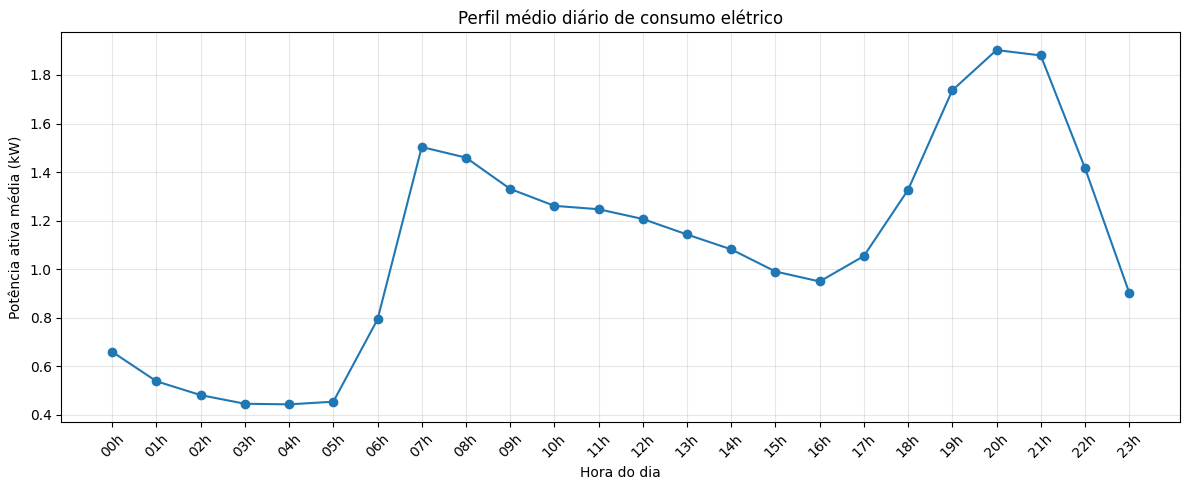

In [8]:
media_horaria = perfil_diario.mean()
plt.figure(figsize=(12, 5))
plt.plot(media_horaria.index, media_horaria.values, marker="o")
plt.title("Perfil médio diário de consumo elétrico")
plt.xlabel("Hora do dia")
plt.ylabel("Potência ativa média (kW)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

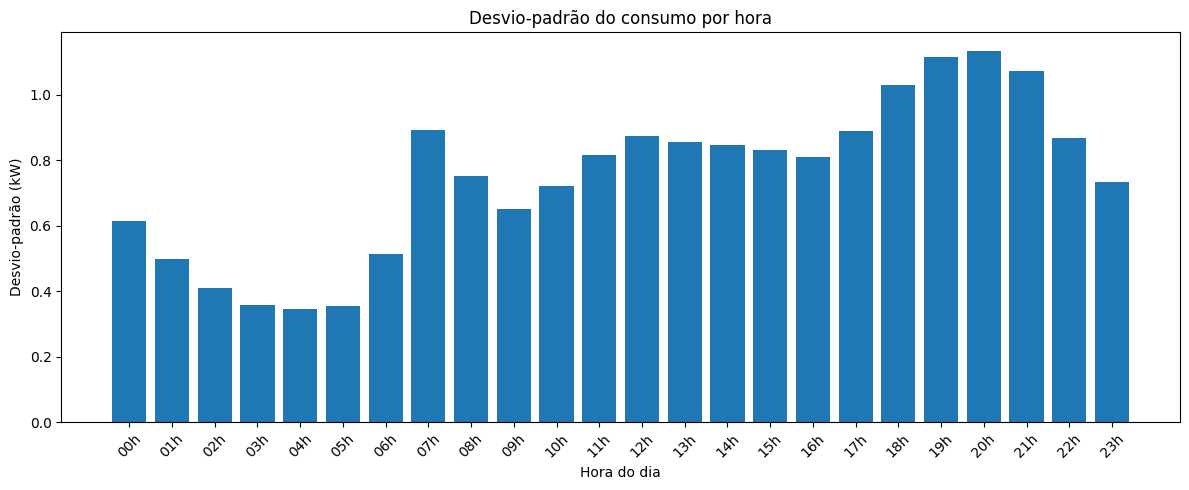

In [9]:
desvio_horario = perfil_diario.std()
plt.figure(figsize=(12, 5))
plt.bar(desvio_horario.index, desvio_horario.values)
plt.title("Desvio-padrão do consumo por hora")
plt.xlabel("Hora do dia")
plt.ylabel("Desvio-padrão (kW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Subconjuntos aninhados (25%, 50%, 75%, 100%)

In [10]:
def gerar_subconjuntos(perfil_diario, semente=42):
    """
    Gera quatro subconjuntos aninhados a partir
    da matriz de perfis diários.

    Cenários:
        C1: 25%
        C2: 50%
        C3: 75%
        C4: 100%

    Parâmetros:
        perfil_diario: DataFrame com 24 atributos horários
        semente: valor para reprodutibilidade

    Retorno:
        Dicionário contendo os quatro subconjuntos.
    """

    # Verificar a estrutura dos dados
    if perfil_diario.shape[1] != 24:
        raise ValueError("A matriz deve possuir 24 atributos.")

    if perfil_diario.isna().any().any():
        raise ValueError("A matriz possui valores ausentes.")

    # Quantidade total de dias
    total_dias = len(perfil_diario)

    # Gerador aleatório com semente fixa
    gerador = np.random.default_rng(semente)

    # Embaralhar os índices uma única vez
    indices = gerador.permutation(total_dias)

    # Percentuais dos cenários
    percentuais = {
        "C1": 0.25,
        "C2": 0.50,
        "C3": 0.75,
        "C4": 1.00
    }

    subconjuntos = {}

    for nome, percentual in percentuais.items():

        # Quantidade de dias no cenário
        quantidade = round(total_dias * percentual)

        # Selecionar os primeiros índices
        indices_selecionados = indices[:quantidade]

        # Construir subconjunto
        subconjunto = perfil_diario.iloc[
            indices_selecionados
        ].copy()

        # Organizar os dias cronologicamente
        subconjunto = subconjunto.sort_index()

        # Armazenar
        subconjuntos[nome] = subconjunto

    return subconjuntos

In [11]:
subconjuntos = gerar_subconjuntos(perfil_diario)
for nome, dados in subconjuntos.items():
    print(f"{nome}: {dados.shape}")

nomes = list(subconjuntos)
for menor, maior in zip(nomes, nomes[1:]):
    resultado = set(subconjuntos[menor].index).issubset(subconjuntos[maior].index)
    print(f"{menor} contido em {maior}: {resultado}")
    assert resultado, f"Falha no aninhamento: {menor} / {maior}"

C1: (353, 24)
C2: (706, 24)
C3: (1058, 24)
C4: (1411, 24)
C1 contido em C2: True
C2 contido em C3: True
C3 contido em C4: True


In [12]:
def salvar_subconjuntos(subconjuntos, pasta="data/subconjuntos"):

    caminho = Path(pasta)
    caminho.mkdir(parents=True, exist_ok=True)

    for nome, dados in subconjuntos.items():

        arquivo = caminho / f"{nome}.csv"

        dados.to_csv(
            arquivo,
            index=True,
            index_label="Dia"
        )

        print(f"Arquivo salvo: {arquivo}")

In [13]:
salvar_subconjuntos(subconjuntos)

Arquivo salvo: data\subconjuntos\C1.csv
Arquivo salvo: data\subconjuntos\C2.csv
Arquivo salvo: data\subconjuntos\C3.csv
Arquivo salvo: data\subconjuntos\C4.csv


## 6. Comparação da representatividade dos subconjuntos

In [14]:
def comparar_subconjuntos(subconjuntos):
    medias = pd.DataFrame()

    for nome, dados in subconjuntos.items():
        medias[nome] = dados.mean()

    print("Médias horárias dos subconjuntos:")
    print(medias.round(3))

    plt.figure(figsize=(12, 6))

    for nome in medias.columns:
        plt.plot(
            medias.index,
            medias[nome],
            marker="o",
            label=nome
        )

    plt.title("Comparação dos perfis médios dos subconjuntos")
    plt.xlabel("Hora do dia")
    plt.ylabel("Potência ativa média (kW)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return medias

Médias horárias dos subconjuntos:
        C1     C2     C3     C4
00h  0.626  0.662  0.659  0.659
01h  0.510  0.541  0.536  0.538
02h  0.458  0.481  0.481  0.481
03h  0.458  0.457  0.450  0.446
04h  0.440  0.451  0.446  0.443
05h  0.426  0.446  0.452  0.454
06h  0.728  0.773  0.782  0.793
07h  1.412  1.478  1.490  1.503
08h  1.409  1.452  1.459  1.460
09h  1.322  1.332  1.323  1.331
10h  1.236  1.260  1.249  1.261
11h  1.225  1.253  1.234  1.247
12h  1.165  1.205  1.190  1.207
13h  1.073  1.147  1.131  1.143
14h  1.076  1.103  1.073  1.082
15h  0.978  1.008  0.991  0.990
16h  0.951  0.957  0.948  0.949
17h  1.031  1.070  1.044  1.054
18h  1.301  1.342  1.318  1.327
19h  1.743  1.758  1.739  1.737
20h  1.885  1.881  1.891  1.903
21h  1.874  1.899  1.877  1.880
22h  1.438  1.444  1.414  1.417
23h  0.932  0.924  0.905  0.904


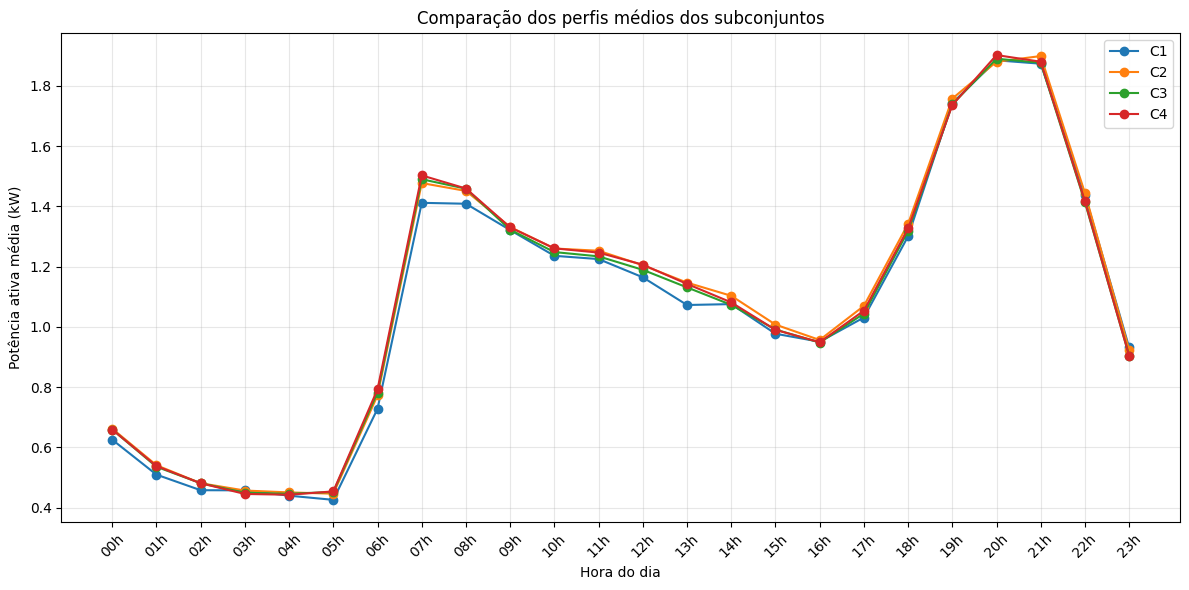

In [15]:
medias_subconjuntos = comparar_subconjuntos(subconjuntos)

In [16]:
#calcular o erro absoluto médio (MAE) entre o perfil 
# médio de cada subconjunto e o perfil médio da 
# base completa (C4)
# Perfil médio da base completa
referencia = medias_subconjuntos["C4"]

print("Comparação com a base completa (C4)")

for nome in ["C1", "C2", "C3"]:
    erro = (
        medias_subconjuntos[nome] - referencia
    ).abs().mean()

    print(f"{nome} - MAE: {erro:.4f} kW")

Comparação com a base completa (C4)
C1 - MAE: 0.0271 kW
C2 - MAE: 0.0120 kW
C3 - MAE: 0.0061 kW


Quanto menor o MAE, mais próximo está o perfil médio do subconjunto em relação ao perfil médio da base completa.

## 7. Execução e avaliação do K-Means


In [17]:
from src.kmeans import executar_kmeans

# Carregar o subconjunto C1
dados_c1 = pd.read_csv(
    "data/subconjuntos/C1.csv",
    index_col="Dia"
)

# Executar o algoritmo
resultado = executar_kmeans(
    dados=dados_c1,
    k=3,
    semente=42
)

print("=== RESULTADOS K-MEANS - C1 ===")
print(f"Quantidade de registros: {len(dados_c1)}")
print(f"Quantidade de atributos: {dados_c1.shape[1]}")
print(f"Tempo de execução: {resultado['tempo_execucao']:.6f} segundos")
print(f"Número de iterações: {resultado['iteracoes']}")
print(f"Inércia: {resultado['inercia']:.4f}")
print(f"Quantidade de clusters: {resultado['quantidade_clusters']}")

=== RESULTADOS K-MEANS - C1 ===
Quantidade de registros: 353
Quantidade de atributos: 24
Tempo de execução: 0.091870 segundos
Número de iterações: 20
Inércia: 3562.2283
Quantidade de clusters: 3


Verificar quantos dias pertencem a cada cluster

avaliar a qualidade dos agrupamentos

In [18]:
from src.metricas import avaliar_agrupamento

# Avaliar os agrupamentos do K-Means
metricas = avaliar_agrupamento(
    dados_c1,
    resultado["rotulos"]
)

print("=== AVALIAÇÃO K-MEANS - C1 ===")
print(f"Silhouette Score: {metricas['silhouette']:.4f}")
print(f"Davies-Bouldin: {metricas['davies_bouldin']:.4f}")
print(f"Calinski-Harabasz: {metricas['calinski_harabasz']:.4f}")

=== AVALIAÇÃO K-MEANS - C1 ===
Silhouette Score: 0.1636
Davies-Bouldin: 1.9118
Calinski-Harabasz: 92.2571


Determinação do número de clusters (k) do K-Means

In [19]:
#testar diferentes valores de k
from src.avaliacao_kmeans import avaliar_valores_k

# Avaliar valores de k entre 2 e 10
resultados_k = avaliar_valores_k(
    dados=dados_c1,
    k_min=2,
    k_max=10
)

# Exibir tabela
print("=== AVALIAÇÃO DOS VALORES DE K ===")

print(resultados_k.round(4).to_string(index=False))

=== AVALIAÇÃO DOS VALORES DE K ===
 k  tempo  iteracoes   inercia  silhouette  davies_bouldin  calinski_harabasz
 2 0.0582          9 4052.1855      0.2249          1.6337           120.2276
 3 0.0498         20 3562.2283      0.1636          1.9118            92.2571
 4 0.0490          7 3300.3393      0.1702          1.9574            75.4269
 5 0.0528         25 3101.3894      0.1244          1.9881            65.6075
 6 0.0523         15 2957.6936      0.1273          1.8854            58.2495
 7 0.0530         15 2845.0638      0.1304          1.9768            52.6004
 8 0.0523         15 2745.6039      0.1217          2.0135            48.3696
 9 0.0532         14 2662.6118      0.1261          1.9265            44.8564
10 0.0577          8 2530.6868      0.1307          1.9333            43.8157


gráficos para comparar as métricas

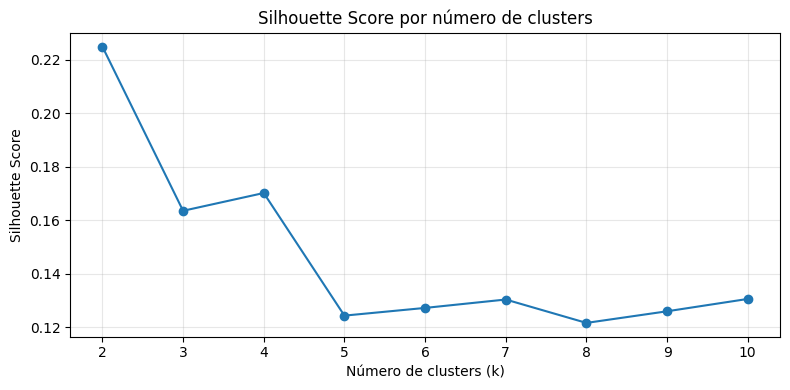

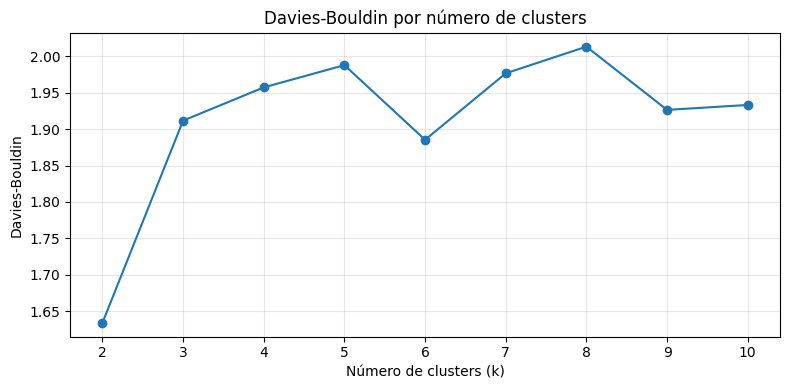

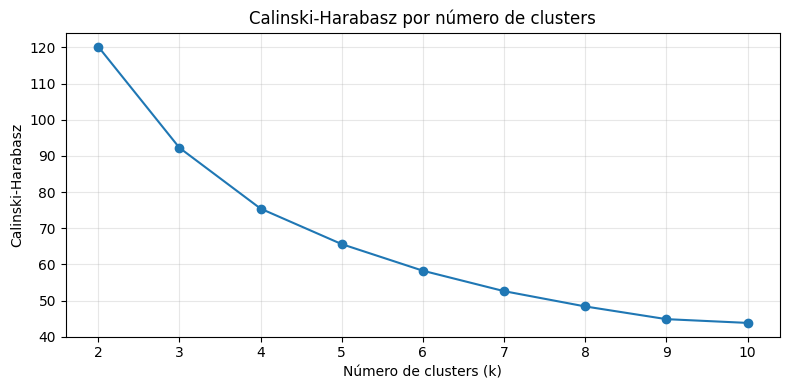

In [20]:
metricas_graficos = [
    ("silhouette", "Silhouette Score"),
    ("davies_bouldin", "Davies-Bouldin"),
    ("calinski_harabasz", "Calinski-Harabasz")
]

for coluna, titulo in metricas_graficos:

    plt.figure(figsize=(8, 4))

    plt.plot(
        resultados_k["k"],
        resultados_k[coluna],
        marker="o"
    )

    plt.title(f"{titulo} por número de clusters")
    plt.xlabel("Número de clusters (k)")
    plt.ylabel(titulo)
    plt.xticks(resultados_k["k"])
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Identificar os melhores valores de k

In [22]:
melhor_silhouette = resultados_k.loc[
    resultados_k["silhouette"].idxmax()
]

melhor_davies = resultados_k.loc[
    resultados_k["davies_bouldin"].idxmin()
]

melhor_calinski = resultados_k.loc[
    resultados_k["calinski_harabasz"].idxmax()
]

print("=== MELHORES VALORES DE K ===")

print(
    "Silhouette:",
    int(melhor_silhouette["k"])
)

print(
    "Davies-Bouldin:",
    int(melhor_davies["k"])
)

print(
    "Calinski-Harabasz:",
    int(melhor_calinski["k"])
)

=== MELHORES VALORES DE K ===
Silhouette: 2
Davies-Bouldin: 2
Calinski-Harabasz: 2


interpretar os perfis de consumo dos clusters

## 8. Interpretação dos clusters com k=2
O valor k=2 é utilizado nesta análise exploratória. Confirme sua adequação com as métricas calculadas anteriormente.

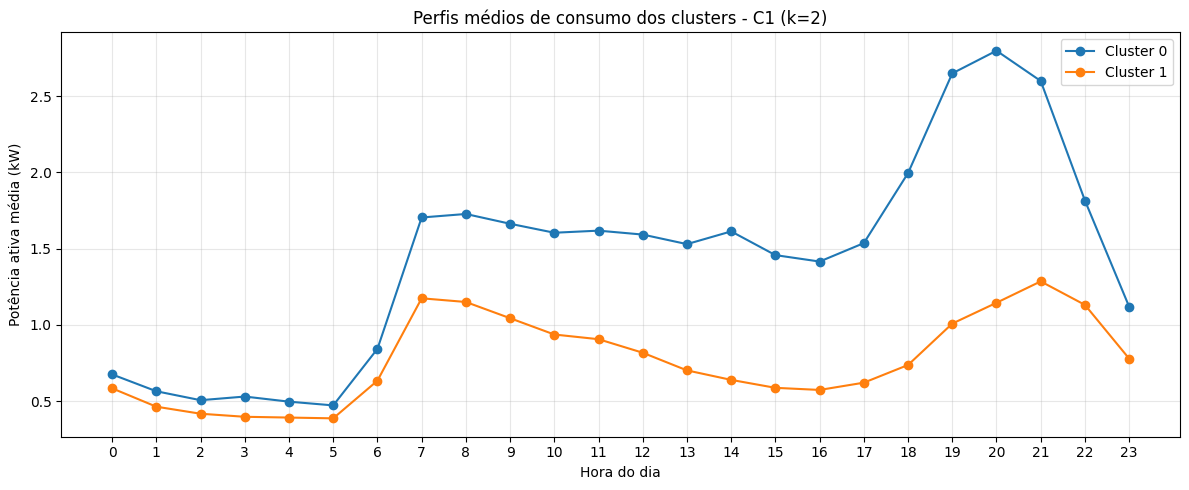

Cluster 0: 158 dias (44.76%)
Cluster 1: 195 dias (55.24%)


In [23]:
# Executar uma única vez o K-Means com k=2
resultado_k2 = executar_kmeans(dados=dados_c1, k=2, semente=42)
centroides = resultado_k2["centroides"]

plt.figure(figsize=(12, 5))
for cluster, centroide in enumerate(centroides):
    plt.plot(range(len(centroide)), centroide, marker="o", label=f"Cluster {cluster}")
plt.title("Perfis médios de consumo dos clusters - C1 (k=2)")
plt.xlabel("Hora do dia")
plt.ylabel("Potência ativa média (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

clusters, quantidades = np.unique(resultado_k2["rotulos"], return_counts=True)
for cluster, quantidade in zip(clusters, quantidades):
    percentual = 100 * quantidade / len(dados_c1)
    print(f"Cluster {cluster}: {quantidade} dias ({percentual:.2f}%)")
